# Project Overview

The project establishes a robust machine learning pipeline to predict flight delays by leveraging historical flight data. It incorporates a range of features, including airline, departure and arrival airports, scheduled and actual times, cargo weight, weather conditions, and other relevant variables, to forecast the likelihood of delays.

**Progressive Model Development**

The project employs a progressive modelling approach, beginning with a Decision Tree as an initial baseline model. This provides an early understanding of the relationships between input features and flight delays. Building on this foundation, the project introduces a Random Forest model— an ensemble technique that combines the outputs of several decision trees to improve accuracy and make the model more stable. The final model is an XGBoost classifier, a gradient boosting algorithm recognised for its strong performance in classification tasks. XGBoost improves prediction accuracy and generalisation by iteratively combining weak learners into a more accurate ensemble.

**Benefits and Significance**

The project offers several key advantages:

- Proactive Delay Management: Predictive modelling enables airlines and logistics providers to manage schedules and resources more proactively, reducing operational disruption.

- Improved Communication: Early delay predictions allow for timely updates to customers and ground handlers, improving coordination across the cargo delivery process and reducing bottlenecks.

- Cost Efficiency: Anticipating delays helps reduce costs associated with cargo storage, missed connections, re-routing, staff overtime, and passenger compensation.

- Operational Optimisation: Predictive insights support more effective resource planning, from ground crew deployment to cargo load management, leading to smoother logistics and improved delivery reliability.

Flight delays present significant economic and operational challenges for the aviation and logistics industries. This project seeks to mitigate these impacts by delivering accurate delay predictions, improving the reliability of air transport. Enhancing operational predictability is vital for maintaining customer satisfaction, ensuring the timely delivery of goods, and reducing financial losses.


## Version note (October 2026)

This is a revised version of the notebook. The first version reported accuracy above 99% for all three models, which turned out to be caused by **data leakage**: some inputs contained information that is only known after a delay has happened.

- **'Total Delay (mins)'** (actual arrival minus planned arrival) was being used as a model input. It is now used for exploratory analysis only and dropped before training.
- **Departure hour, day of week and time of day** were taken from the actual departure time. They now come from the planned departure time, which is known in advance.
- Airline and airport codes have been anonymised (Airline A to T, Origin 1 to 7, Destination 01 to 38).

All results, charts and commentary below come from the corrected run. The modelling approach and the reasoning behind the final model choice are unchanged.

# Import Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier

import os
os.makedirs('images', exist_ok=True)  # charts used on the project page are saved here


## Set Functions

Defining functions at the outset of the code enhances organisation, readability, and reusability. This practice helps structure the workflow more clearly and reduces repetition by encapsulating commonly used procedures, such as plotting or model training, within reusable blocks.

- plot_bar: This function acts as a template for generating bar charts. It takes inputs including the dataset and axis labels, and then automatically creates a bar chart using the Seaborn visualisation library.

- run_grid_search: This function automates hyperparameter tuning for machine learning models. It systematically tests combinations of model parameters and selects the configuration that achieves the highest predictive accuracy.

In [2]:
# Set consistent plotting style
sns.set_theme()
sns.set_palette('cubehelix')

# Plot Function
def plot_bar(x, y, data, title, xlabel, ylabel, figsize=(8, 6), rotation=None):
    plt.figure(figsize=figsize)
    sns.barplot(x=x, y=y, data=data)
    plt.title(title, fontsize=16, fontweight='bold')
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    if rotation:
        plt.xticks(rotation=rotation, ha='right')
    plt.tight_layout()
    plt.show()

In [3]:
# Function to run grid search for hyperparameter tuning
def run_grid_search(model, param_grid, X_train_scaled, y_train, X_test_scaled, y_test, scoring='accuracy'):
    grid = GridSearchCV(model, param_grid, cv=5, scoring=scoring, verbose=1, n_jobs=-1)
    grid.fit(X_train_scaled, y_train)  # Fit on training data
    best_model = grid.best_estimator_

    predictions = best_model.predict(X_test_scaled)

    print(f"\nBest Parameters for {model.__class__.__name__}: {grid.best_params_}")
    print(f"Best CV Score: {grid.best_score_:.4f}")
    print("Test Set Performance:")
    print(classification_report(y_test, predictions))

    return best_model, predictions

# Load and Explore the Dataset


In [4]:
dataset = pd.read_csv('flight_delays - Copy.csv')

In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Airline                         4000 non-null   str    
 1   Departure Airport               4000 non-null   str    
 2   Arrival Airport                 4000 non-null   str    
 3   Aircraft Type                   4000 non-null   str    
 4   Departure Planned Time          4000 non-null   str    
 5   Departure Time                  4000 non-null   str    
 6   Arrival Planned Time            4000 non-null   str    
 7   Arrival Time                    4000 non-null   str    
 8   Distance                        4000 non-null   int64  
 9   Number of Containers            3981 non-null   float64
 10  Cargo Weight                    3975 non-null   float64
 11  Freight Load Factor             3978 non-null   float64
 12  Cargo Type                      4000 non-null

In [6]:
dataset.describe()

,Distance,Number of Containers,Cargo Weight,Freight Load Factor
count,4000.000000,3981.000000,3975.000000,3978.000000
mean,7721.343250,22.929917,8800.992956,75.781435
std,2524.118459,13.669607,5842.927487,10.987614
min,1010.000000,1.000000,1000.000000,50.030000
25%,6000.500000,11.000000,3542.500000,66.780000
50%,7850.000000,20.000000,7712.000000,76.010000
75%,9680.500000,34.000000,13964.000000,85.107500
max,11998.000000,49.000000,19996.000000,94.990000


In [7]:
dataset.head()

,Airline,Departure Airport,Arrival Airport,Aircraft Type,Departure Planned Time,Departure Time,Arrival Planned Time,Arrival Time,Distance,Number of Containers,Cargo Weight,Freight Load Factor,Cargo Type,Priority Cargo,Special Handling,Temperature-Controlled Freight,Dangerous Goods,Peak Freight Season,Departure Weather Conditions,Delay
0,Airline N,Origin 5,Destination 05,A380,12/04/2024 19:28,12/04/2024 19:43,12/04/2024 21:28,12/04/2024 21:43,2961,10.0,1902.0,80.34,Perishables,No,Yes,No,Yes,Yes,Clear,Yes
1,Airline N,Origin 1,Destination 26,A350,02/08/2024 10:10,02/08/2024 11:10,02/08/2024 15:10,02/08/2024 16:10,2936,10.0,1447.0,63.79,Pharmaceuticals,Yes,No,No,Yes,Yes,Snow,Yes
2,Airline C,Origin 2,Destination 30,B787,14/09/2024 23:43,15/09/2024 01:47,15/09/2024 00:43,15/09/2024 02:47,2793,13.0,4037.0,79.36,Electronics,No,No,No,No,No,Rain,Yes
3,Airline A,Origin 3,Destination 11,B787,09/11/2024 21:43,09/11/2024 22:00,10/11/2024 01:43,10/11/2024 02:00,1945,5.0,4304.0,73.62,Perishables,No,Yes,No,No,No,Rain,Yes
4,Airline J,Origin 1,Destination 08,A380,06/07/2024 15:14,06/07/2024 15:37,06/07/2024 20:14,06/07/2024 20:37,3437,16.0,1000.0,89.12,Electronics,No,Yes,No,No,No,Rain,Yes


#Feature Engineer

Feature engineering is the process of creating new variables from existing data to improve the performance of machine learning models. By transforming raw data into more informative features, this process enables models to learn underlying patterns more effectively and generate more accurate predictions.

Why It Matters:

- **Improved Predictive Accuracy:** Creating features that better represent the relationships within the data can significantly enhance model performance.

- **Captures Complexity:** Feature engineering allows for the representation of non-linear or hidden patterns that may not be captured by basic features alone.

- **Enhanced Interpretability:** Engineered features can sometimes offer more intuitive or meaningful insights, making the model's behaviour easier to understand and explain.

Taking Care of Missing values

In this project, missing values in numerical columns such as Distance and Cargo Weight were filled using the mean of each column. This is a standard approach that ensures the dataset remains usable for modelling.

While imputing with the mean can introduce bias in cases of large or skewed missing data, this is not a concern here, as the number of missing values is minimal and the technique is considered appropriate for the dataset used.

In [8]:
print(dataset.isnull().sum())


Airline                            0
Departure Airport                  0
Arrival Airport                    0
Aircraft Type                      0
Departure Planned Time             0
Departure Time                     0
Arrival Planned Time               0
Arrival Time                       0
Distance                           0
Number of Containers              19
Cargo Weight                      25
Freight Load Factor               22
Cargo Type                         0
Priority Cargo                     0
Special Handling                   0
Temperature-Controlled Freight     0
Dangerous Goods                    0
Peak Freight Season                0
Departure Weather Conditions       0
Delay                              0
dtype: int64


In [9]:
# Fill missing Departure time
numeric_columns = ['Distance', 'Cargo Weight', 'Number of Containers', 'Freight Load Factor']
for column in numeric_columns:
    dataset[column] = dataset[column].fillna(dataset[column].mean())

In [10]:
# Convert columns to datetime objects
date_columns = ['Departure Planned Time','Departure Time','Arrival Planned Time','Arrival Time']
for column in date_columns:
    dataset[column] = pd.to_datetime(dataset[column], format='%d/%m/%Y %H:%M', dayfirst=True)

Enriching dataset

Date and time columns were converted to datetime objects, and timing features were extracted: 'Day of Week', 'Departure Hour' and 'Time of Day'. These allow the models to pick up patterns linked to when a flight is scheduled.

These features are taken from the **planned** departure time, not the actual one. The aim is to predict a delay before the flight leaves, and the actual departure time is only known once a delay has already happened.

In [11]:
# Extract the day of the week from the planned departure date (known before the flight)
dataset['Day of Week'] = dataset['Departure Planned Time'].dt.dayofweek

In [12]:
# Extract the planned departure hour (known before the flight)
dataset['Departure Hour'] = dataset['Departure Planned Time'].dt.hour

# Create the time of day categories
def get_time_of_day(hour):
    if 0 <= hour < 6:
        return 'Night'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

dataset['Time of Day'] = dataset['Departure Hour'].apply(get_time_of_day)

'Flight Duration (hrs)' and 'Total Delay (mins)' were calculated to quantify the delay aspect.

**Important:** 'Total Delay (mins)' is calculated from the *actual* arrival time, so it is only known after the flight lands. It is used here for exploratory analysis only and is **excluded from the model inputs** (see the Data Leakage Correction note at the top of the notebook).

In [13]:
# Calculate flight duration in hours
dataset['Flight Duration (hrs)'] = (dataset['Arrival Planned Time'] - dataset['Departure Planned Time']).dt.total_seconds() / 3600

In [14]:
# Calculate total delay in minutes
dataset['Total Delay (mins)'] = (dataset['Arrival Time'] - dataset['Arrival Planned Time']).dt.total_seconds() / 60

A 'Cargo_Density' feature was engineered by dividing 'Cargo Weight' by 'Number of Containers'. This potentially captures the relationship between cargo distribution and delays.

In [15]:
# Calculate cargo density as Cargo Weight divided by Number of Containers
dataset['Cargo_Density'] = dataset['Cargo Weight'] / dataset['Number of Containers']

The 'Delay Severity' feature was created to categorise delays into different levels (No Delay, Minor, Moderate, Severe), providing insights into the distribution and types of delays within the dataset. However, due to the potential for multicollinearity with the 'Delay' column (our target variable), this feature will be removed before model training. Although not used for prediction, it offers valuable insights into the characteristics of flight delays.

In [16]:
# Define a function to calculate delay severity
def calculate_severity(delay_minutes):
    if delay_minutes <= 0:
        return "No Delay"
    elif 0 < delay_minutes <= 30:
        return "Minor"
    elif 31 <= delay_minutes <= 60:
        return "Moderate"
    else:
        return "Severe"

# Apply the function to the Total Delay column
dataset['Delay Severity'] = dataset['Total Delay (mins)'].apply(calculate_severity)

In [17]:
print("Delay Severity Distribution:")
print(dataset['Delay Severity'].value_counts(normalize=True))
print("\nDetail Distribution:")
print(dataset['Delay Severity'].value_counts())

Delay Severity Distribution:
Delay Severity
No Delay    0.58025
Severe      0.20150
Minor       0.12650
Moderate    0.09175
Name: proportion, dtype: float64

Detail Distribution:
Delay Severity
No Delay    2321
Severe       806
Minor        506
Moderate     367
Name: count, dtype: int64


# Exploratory Data Analysis

Exploratory Data Analysis (EDA) is an essential step in any data science project. It involves employing visual and statistical techniques to understand the characteristics of the dataset, identify patterns, uncover relationships between variables, and detect potential anomalies. EDA provides valuable insights that guide subsequent data preprocessing, feature engineering, and model building decisions.

/tmp/ipykernel_274/2787526623.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Delay Severity', data=dataset, palette='mako', order=dataset['Delay Severity'].value_counts().index)


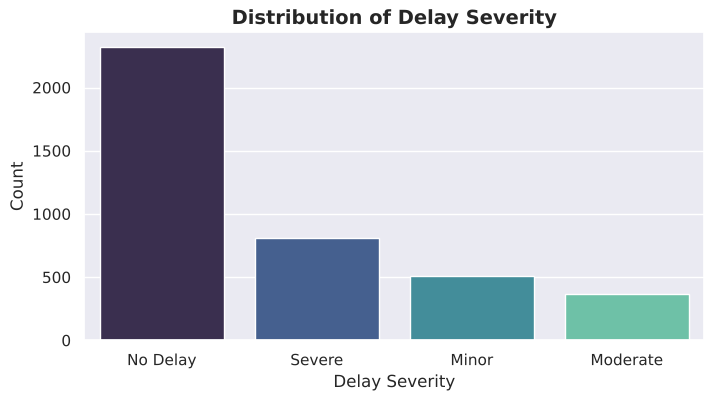

In [18]:
#Delay by Severity
plt.figure(figsize=(8, 4))
sns.countplot(x='Delay Severity', data=dataset, palette='mako', order=dataset['Delay Severity'].value_counts().index)
plt.title('Distribution of Delay Severity',fontsize=14, fontweight='bold')
plt.xlabel('Delay Severity')
plt.ylabel('Count')
plt.show()

This bar chart reveals the distribution of flight delays based on their severity levels. It illustrates the proportion of flights falling into each category: 'No Delay', 'Minor', 'Moderate', and 'Severe'. One can observe the frequency of each delay severity, highlighting potential areas of concern for operational efficiency.

While most delays fall into the 'No Delay' category, a significant portion is categorised as 'Severe', followed by 'Minor' and 'Moderate' delays.

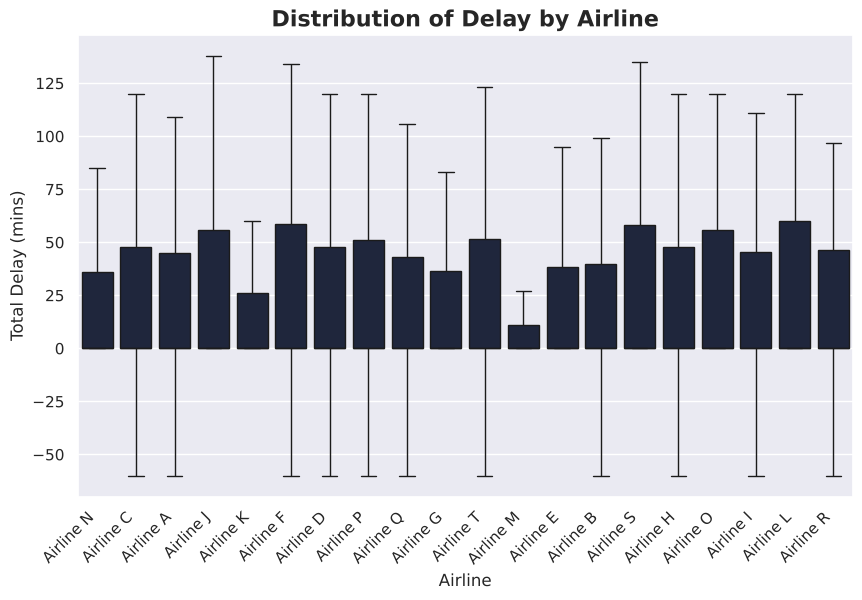

In [19]:
 # Delay by Airline
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(x='Airline', y='Total Delay (mins)', data=dataset, showfliers=False)  # showfliers=False to hide outliers if desired
plt.title('Distribution of Delay by Airline', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for readability
plt.show()

This box plot compares total delay times across airlines. Airline identities have been anonymised (Airline A to T), and departure and arrival airports have been relabelled as Origin and Destination numbers.

Most airlines show a similar spread of delays, typically from slightly early to around two hours late. A few airlines stand out with a noticeably narrower range (for example, Airline M), which would be worth investigating with real operational data: the difference could come from route mix, network congestion or fleet age rather than the airline itself.

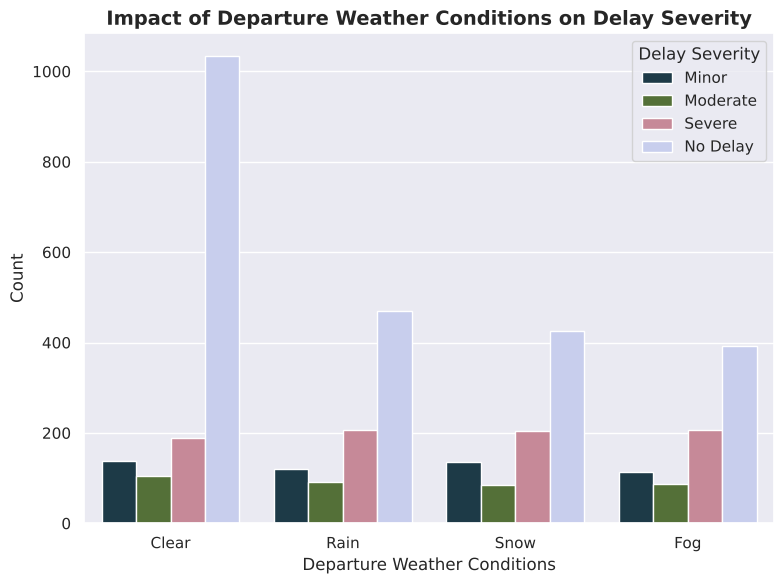

In [20]:
# Weather Conditions vs. Delay Severity
plt.figure(figsize=(8, 6))
sns.countplot(x='Departure Weather Conditions', hue='Delay Severity', data=dataset, palette='cubehelix', order=dataset['Departure Weather Conditions'].value_counts().index)
plt.title('Impact of Departure Weather Conditions on Delay Severity', fontsize=14, fontweight='bold')
plt.xlabel('Departure Weather Conditions', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(title='Delay Severity')
plt.tight_layout()
plt.savefig('images/flight-weather-vs-severity.png', dpi=150)
plt.show()

This count plot examines the relationship between departure weather conditions and the severity of delays.

Weather clearly affects **whether** a flight is delayed: only 34% of flights in clear weather were delayed, compared with 58% in rain, 62% in fog and 67% in snow. However, the number of **severe** delays is almost identical in every condition (188 to 207 flights). Poor weather turns more flights into delayed flights, but it does not explain which delays become severe, so other operational factors must be involved.

/tmp/ipykernel_274/3939811374.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Day of Week', y='Total Delay (mins)', data=dataset , palette='cubehelix', showfliers=False)


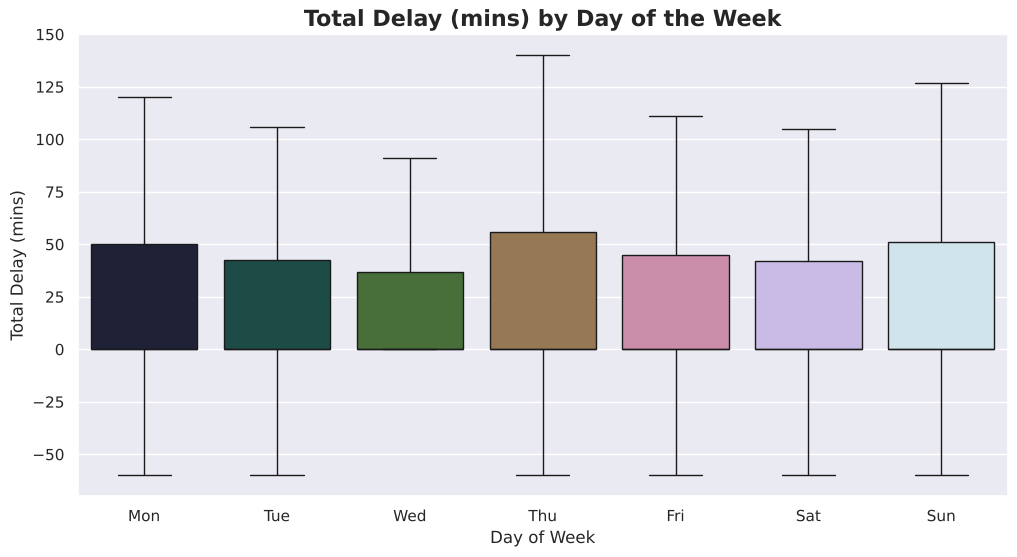

In [21]:
# Box plot for Total Delay by Day of the Week
plt.figure(figsize=(12, 6))
sns.boxplot(x='Day of Week', y='Total Delay (mins)', data=dataset , palette='cubehelix', showfliers=False)
plt.title('Total Delay (mins) by Day of the Week', fontsize=16, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Total Delay (mins)', fontsize=12)
plt.xticks(ticks=range(7), labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.show()

This box plot shows the distribution of total delay times across the days of the week.

The median delay is 0 minutes on every day, and the spread is broadly similar across the week. Thursday and Sunday show slightly longer upper ranges, while Wednesday has the narrowest. There is no strong day-of-week pattern, which suggests scheduling day alone is not a major driver of delay in this dataset.

/tmp/ipykernel_274/3233829110.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Peak Freight Season', y='Total Delay (mins)',palette= 'cubehelix', data=dataset, showfliers=False)


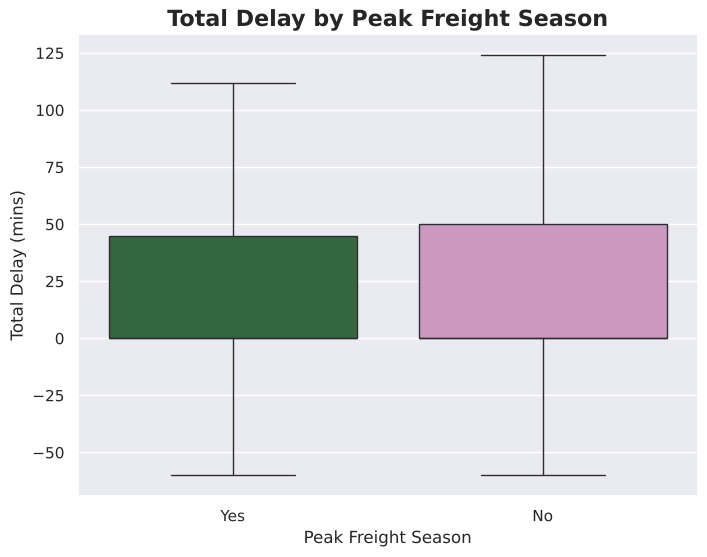

In [22]:
#  Box plots for 'Total Delay (mins)' across different 'Peak Freight Season'.
plt.figure(figsize=(8, 6))
sns.boxplot(x='Peak Freight Season', y='Total Delay (mins)',palette= 'cubehelix', data=dataset, showfliers=False)
plt.title('Total Delay by Peak Freight Season', fontsize=16, fontweight='bold')
plt.show()

This box plot compares total delay times in peak and non-peak freight seasons.

The two distributions are very similar: the delay rate is 52% in both, and the median delay is 0 minutes in each. Contrary to what might be expected, peak season on its own does not appear to increase delays in this dataset.

/tmp/ipykernel_274/3756655744.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Weight Category', y='Total Delay (mins)', data=dataset, palette="cubehelix")


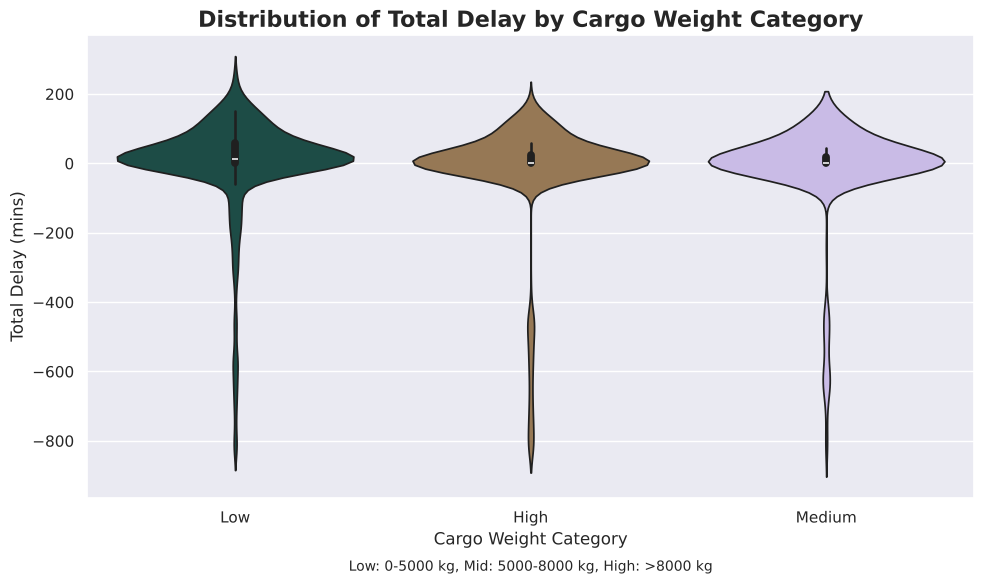

In [23]:
# Distribution of Total Delay by Cargo Weight Category
plt.figure(figsize=(10, 6))

# Define weight categories based on 'Cargo Weight'
def weight_category(weight):
    if weight <= 5000:
        return 'Low'
    elif 5000 < weight <= 8000:
        return 'Medium'
    else:
        return 'High'

# Apply the function to create the 'Weight Category' column
dataset['Weight Category'] = dataset['Cargo Weight'].apply(weight_category)

# Create the violin plot with 'hue' for different Weight Categories
sns.violinplot(x='Weight Category', y='Total Delay (mins)', data=dataset, palette="cubehelix")

plt.title('Distribution of Total Delay by Cargo Weight Category',fontsize=16, fontweight='bold')
plt.xlabel('Cargo Weight Category')
plt.ylabel('Total Delay (mins)')

# Add text explanation for weight categories below the x-axis (optional)
plt.text(0.5, -0.15, "Low: 0-5000 kg, Mid: 5000-8000 kg, High: >8000 kg",
         ha='center', va='center', transform=plt.gca().transAxes, fontsize=10)

plt.tight_layout()
plt.show()

This violin plot shows the distribution of total delay times across cargo weight categories (Low up to 5,000 kg, Medium 5,000 to 8,000 kg, High above 8,000 kg).

Interestingly, lighter loads show the widest spread of delays, with a median delay of 12 minutes for the Low category compared with 0 minutes for Medium and High. Heavier cargo is not associated with longer delays here, so weight is more likely to matter in combination with other factors than on its own.

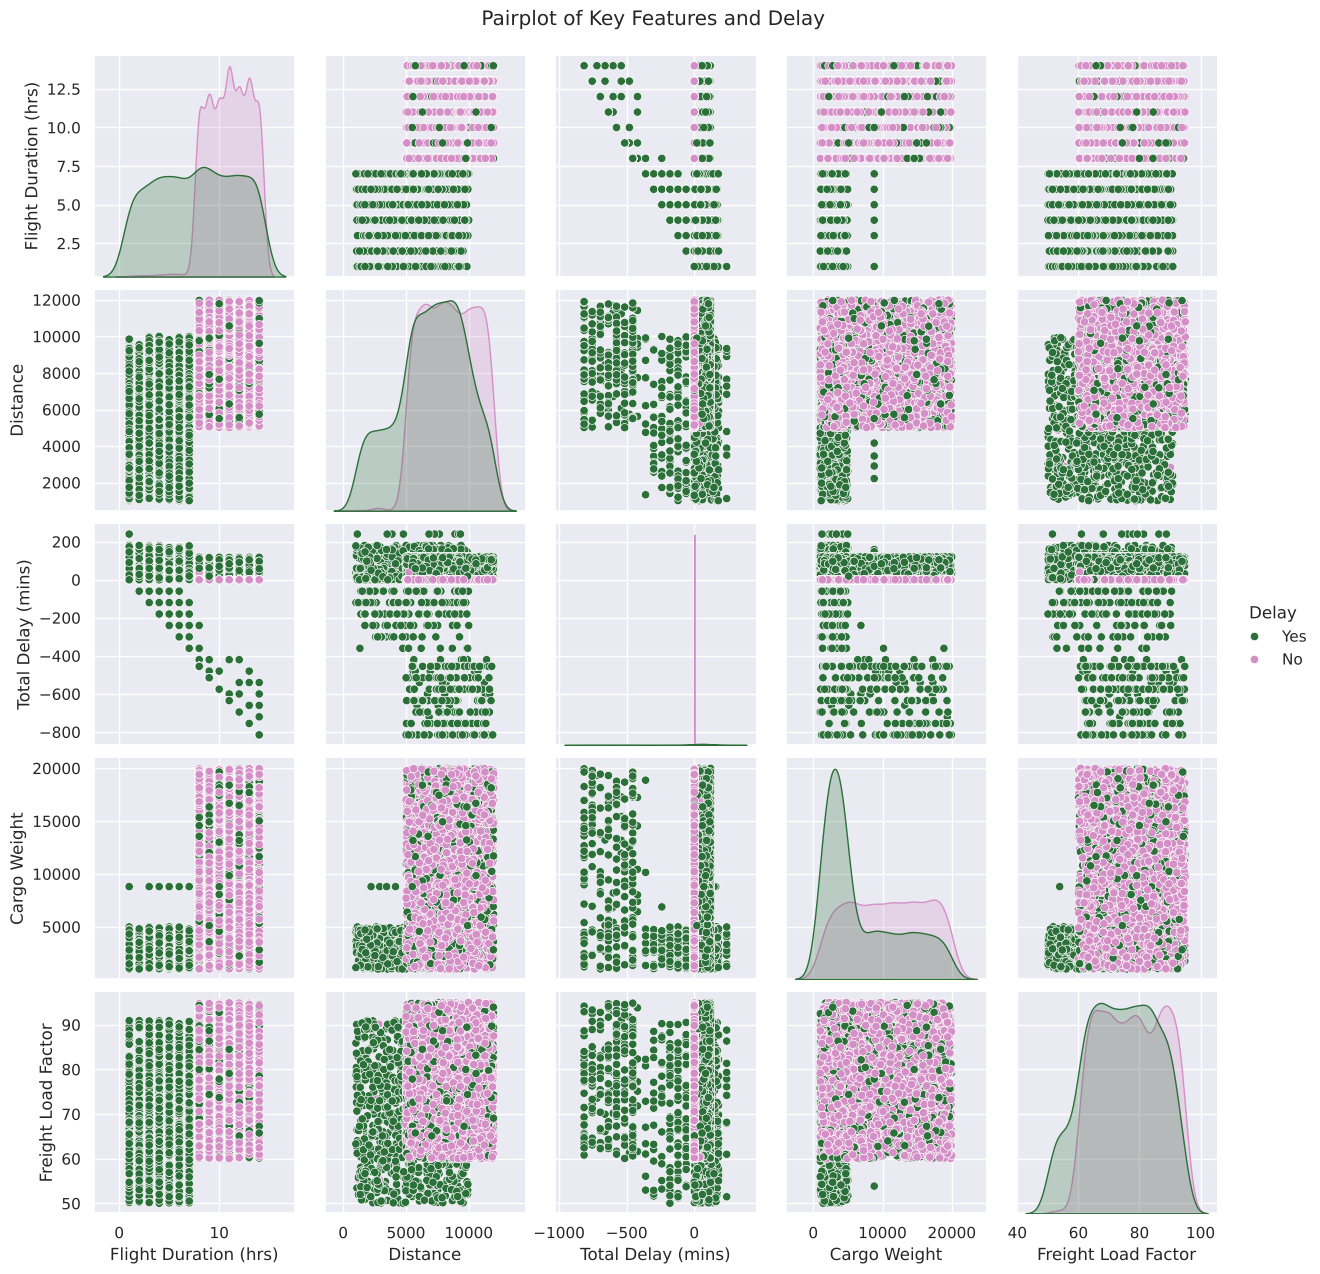

In [24]:
# Pairplot for key features and delay
sns.pairplot(dataset, vars=['Flight Duration (hrs)', 'Distance', 'Total Delay (mins)', 'Cargo Weight', 'Freight Load Factor'], hue='Delay',palette='cubehelix')
plt.suptitle('Pairplot of Key Features and Delay', y=1.02)
plt.show()

This pairplot shows the relationships between the key numerical features (flight duration, distance, total delay, cargo weight and freight load factor), coloured by whether the flight was delayed.

Delayed and on-time flights overlap heavily on every individual feature. Flight duration, distance and cargo weight are related to each other, but none of them separates delayed from on-time flights on its own. This supports using tree-based models, which can learn from combinations of features rather than single relationships.

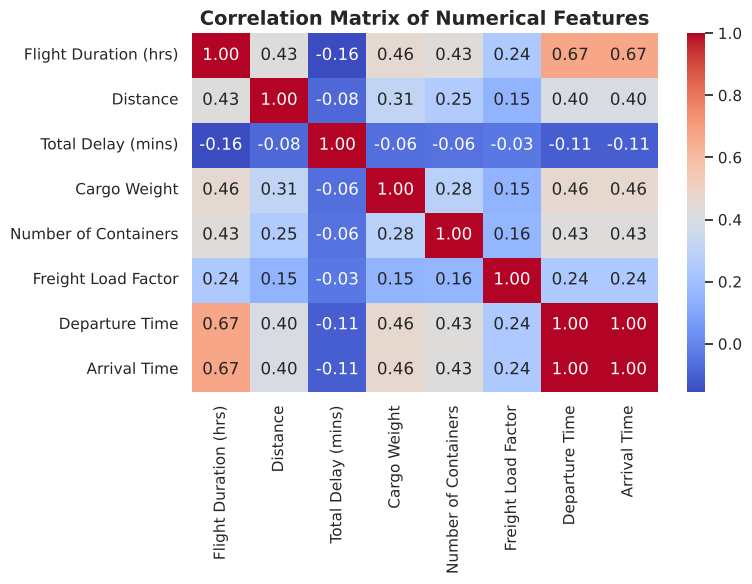

In [25]:
# Heatmap of Correlation Matrix
plt.figure(figsize=(8, 6))
correlation_matrix = dataset[['Flight Duration (hrs)','Distance', 'Total Delay (mins)', 'Cargo Weight', 'Number of Containers','Freight Load Factor','Departure Time','Arrival Time']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features',fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('images/flight-correlation-heatmap.png', dpi=150)
plt.show()

This heatmap shows the correlation matrix for key numerical features.

As expected, Flight Duration and Distance are positively correlated (0.43), as are Cargo Weight and Number of Containers with Flight Duration. Total Delay, however, shows only **weak negative** correlations with every numerical feature (between -0.16 and -0.03). No single numerical variable explains delay on its own, which suggests delays are driven by a combination of factors (such as weather and handling) rather than by flight length or cargo size alone.

Departure Time and Arrival Time are timestamps and their correlations here are not meaningful; they are dropped before modelling.

#OneHot Encoding categorical data

Machine learning algorithms typically perform best with numerical input. However, real-world datasets often include categorical features—variables that represent categories or labels, such as airline names, weather conditions, or cargo types. To make these features suitable for modelling, they must be converted into a numerical format through a process known as encoding.

One-hot encoding is a widely used technique for this purpose. It transforms each categorical variable into a set of binary columns, where each column represents a unique category. A value of 1 indicates the presence of a category in a given observation, while 0 indicates its absence.

Here's how it works:

Identify unique categories: For a given categorical feature (e.g., 'Airline'), list all the unique categories (e.g., 'United', 'American', 'Delta').

For each unique category, create a new feature column. In each new feature column, assign a value of 1 if the original data point belongs to that category and 0 otherwise.

In [26]:
# List of variables to map
varlist =  ['Temperature-Controlled Freight', 'Dangerous Goods', 'Delay','Peak Freight Season','Priority Cargo', 'Special Handling']

# Defining the map function
def binary_map(x):
    return x.map({'Yes': 1, "No": 0})

# Applying the function to the housing list
dataset[varlist] = dataset[varlist].apply(binary_map)

# Encoding categorical data

In this notebook, the pd.get_dummies function from the pandas library is used to apply one-hot encoding to categorical features such as Airline, Time of Day, and Departure Airport. The parameter drop_first=True is specified to remove the first category from each feature, reducing the risk of multicollinearity—where highly correlated variables can negatively affect model performance. This approach helps to improve model stability and reliability.

In [27]:
# Creating a dummy variable for some of the categorical variables and dropping the first one.
categorical_cols = ['Airline','Time of Day','Departure Airport', 'Arrival Airport', 'Aircraft Type', 'Cargo Type', 'Departure Weather Conditions','Weight Category']
dummy = pd.get_dummies(dataset[categorical_cols], drop_first=True)
dummy = dummy.astype(int)
dataset = pd.concat([dataset, dummy], axis=1)
dataset = dataset.drop(categorical_cols, axis=1)


In [28]:
# Drop the specified columns
# 'Total Delay (mins)' is removed here: it is only known after the flight lands, so keeping it as a
# model input leaks the answer (see the 'Data leakage correction' note at the top of the notebook).
dataset.drop(['Departure Planned Time', 'Departure Time', 'Arrival Planned Time', 'Arrival Time','Delay Severity','Total Delay (mins)','Weight Category_Low','Weight Category_Medium'], axis=1, inplace=True)

# Train Test Split


Before training a machine learning model, it's crucial to divide the dataset into two subsets: a training set and a testing set.

Training Set: This portion of the data (typically 70-80%) is used to train the model, allowing it to learn patterns and relationships within the data.
Testing Set: The remaining portion (typically 20-30%) is held out and used to evaluate the model's performance on unseen data. This helps assess how well the model generalises to new, unseen instances.
Why Split the Data?

Splitting the data is essential to avoid overfitting, where the model memorises the training data too well and performs poorly on new data. By evaluating the model on a separate testing set, we get a more realistic estimate of its real-world performance.

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
# Split data into training and testing sets
X = dataset.drop('Delay',axis=1)
y = dataset['Delay']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

## Scaling


Scaling transforms numerical features to a consistent range or distribution. Common techniques include standardisation (centering values around zero with a standard deviation of one) and normalisation (scaling values between 0 and 1). These methods are particularly important for algorithms that rely on distance calculations or gradient-based optimisation.

In this project, scaling was applied for consistency, but it is not essential for the chosen models. These tree-based algorithms split data based on feature thresholds rather than distances, so they are unaffected by the scale of input features.

While scaling does not impact performance in this case, including it in the pipeline maintains consistency and supports future experimentation with models that are sensitive to feature scale.

In [31]:
# Scale numerical features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Initialise Model Training and Evaluation

This code block sets up the environment for model training and evaluation by:

- Displaying an informative message to the console.
- Initialising empty dictionaries to store trained models and their corresponding predictions.

This structure helps keep the workflow organised, making it easier to manage multiple models and compare their performance during evaluation. It supports clear, structured decision-making when selecting the most effective model.

In [32]:
print("\nTraining and Evaluating Models...")
models = {}
predictions = {}


Training and Evaluating Models...


To evaluate the performance of each model, the following techniques are employed:

**Cross-validation**: Used to assess generalisation and model robustness across different subsets of the data.

**Grid Search**: Applied to fine-tune hyperparameters and optimise model performance.

**Learning Curves**: Used to analyse the model’s learning behaviour and detect signs of overfitting or underfitting.

Models are evaluated using key performance metrics, including accuracy, precision, recall, F1-score, and ROC-AUC. These results inform the selection of the most suitable model for predicting flight delays.



#Decision Tree Model

Decision trees are a popular type of machine learning model known for their interpretability and ease of understanding. They work by recursively partitioning the data based on features to create a tree-like structure that leads to predictions.


## Train the Dection Tree Model

In [33]:
from sklearn.tree import DecisionTreeClassifier

In [34]:
dtree = DecisionTreeClassifier(random_state=42)

In [35]:
dtree.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

## Predictions and Evaluation of Decision Tree


In [36]:
dt_predictions = dtree.predict(X_test_scaled)

In [37]:
print(classification_report(y_test,dt_predictions))

              precision    recall  f1-score   support

           0       0.67      0.67      0.67       571
           1       0.70      0.71      0.70       629

    accuracy                           0.69      1200
   macro avg       0.69      0.69      0.69      1200
weighted avg       0.69      0.69      0.69      1200



In [38]:
print(confusion_matrix(y_test,dt_predictions))

[[382 189]
 [184 445]]


**Result (baseline Decision Tree):** 69% accuracy on the test set. The model catches 71% of delayed flights (445 of 629), but 189 on-time flights are wrongly flagged as delayed. This is a reasonable starting point and confirms that the pre-departure features carry a genuine signal.

## Cross Validation

In [39]:
from sklearn.model_selection import cross_val_score
cv_scores_dt = cross_val_score(dtree, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("\nDecision Tree Cross-Validation Scores (Training):", cv_scores_dt)
print(f"Average CV Score: {cv_scores_dt.mean():.2f} (+/- {cv_scores_dt.std()*2:.2f})")


Decision Tree Cross-Validation Scores (Training): [0.67142857 0.67678571 0.69642857 0.67857143 0.65535714]
Average CV Score: 0.68 (+/- 0.03)


**Result:** cross-validation accuracy averages 0.68 across five folds, close to the test score. The baseline is consistent, but an unconstrained tree is likely to be fitting noise, which grid search should address.

##Grid Search Decision Tree

In [40]:
param_grid_dt = {
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
models['Decision Tree'], predictions['Decision Tree'] = run_grid_search(dtree, param_grid_dt,
                                                                        X_train_scaled, y_train,
                                                                        X_test_scaled, y_test)

Fitting 5 folds for each of 36 candidates, totalling 180 fits



Best Parameters for DecisionTreeClassifier: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV Score: 0.7029
Test Set Performance:
              precision    recall  f1-score   support

           0       0.71      0.77      0.74       571
           1       0.77      0.72      0.74       629

    accuracy                           0.74      1200
   macro avg       0.74      0.74      0.74      1200
weighted avg       0.74      0.74      0.74      1200



**Result (tuned Decision Tree):** limiting the tree to a depth of 10 lifts cross-validation accuracy to 0.703 and test accuracy to 74%, with 72% recall and 77% precision. Constraining the tree's complexity made it generalise better.

## Learning Curve for Decision Tree

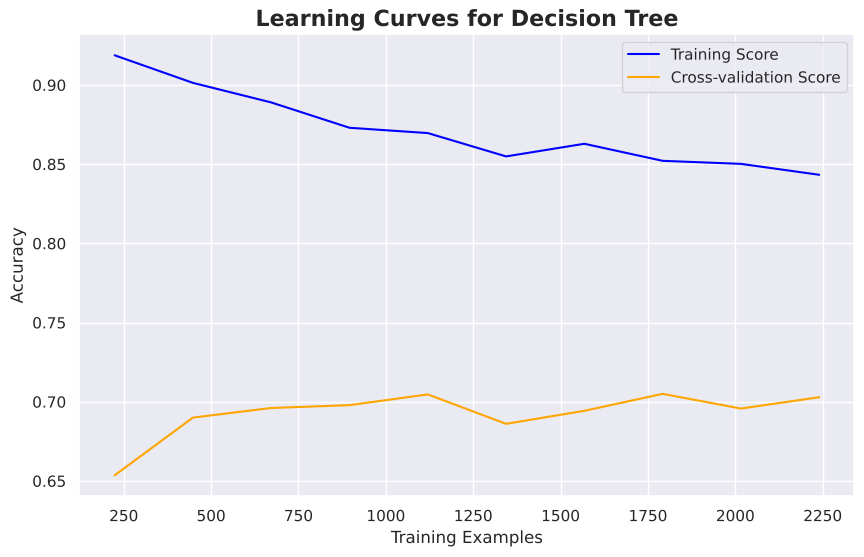

In [41]:
train_sizes, train_scores, test_scores = learning_curve(models['Decision Tree'], X_train_scaled, y_train, cv=5,
                                                        n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10),
                                                        scoring='accuracy')
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training Score', color='blue')
plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation Score', color='orange')
plt.xlabel('Training Examples')
plt.ylabel('Accuracy')
plt.title('Learning Curves for Decision Tree', fontsize=16, fontweight='bold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

**Result:** training accuracy falls from about 0.92 to 0.84 as more data is added, while validation accuracy rises slowly to about 0.70. The gap between the two lines shows the tree still overfits somewhat, which is typical of a single decision tree.

#Random Forest model

Random Forests are an ensemble learning method that combines multiple decision trees to improve predictive accuracy and robustness. They work by training individual trees on different subsets of the data and averaging their predictions.

## Training the Random Forest model

In [42]:
rfc = RandomForestClassifier(n_estimators=100, criterion = 'entropy', random_state = 42)

In [43]:
rfc.fit(X_train_scaled, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boot

## Predictions and Evaluation of Random Forest


In [44]:
rf_predictions = rfc.predict(X_test_scaled)

In [45]:
print(classification_report(y_test,rf_predictions))

              precision    recall  f1-score   support

           0       0.67      0.90      0.77       571
           1       0.87      0.60      0.71       629

    accuracy                           0.74      1200
   macro avg       0.77      0.75      0.74      1200
weighted avg       0.78      0.74      0.74      1200



In [46]:
print(confusion_matrix(y_test,rf_predictions))

[[515  56]
 [250 379]]


**Result (baseline Random Forest):** 74% accuracy, already better than the baseline tree. It is very precise (87% of flights it flags are genuinely delayed, with only 56 false alarms), but it catches 60% of delays.

## Cross Validation

In [47]:
cv_scores_rf = cross_val_score(rfc, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("\nRandom Forest Cross-Validation Scores (Training):", cv_scores_rf)
print(f"Average CV Score: {cv_scores_rf.mean():.2f} (+/- {cv_scores_rf.std()*2:.2f})")


Random Forest Cross-Validation Scores (Training): [0.69464286 0.71964286 0.725      0.71964286 0.68928571]
Average CV Score: 0.71 (+/- 0.03)


**Result:** cross-validation accuracy averages 0.71 with low variation across folds, more stable than the single Decision Tree.

## Grid Search Random Forest

In [48]:
param_grid_rf = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
models['Random Forest'], predictions['Random Forest'] = run_grid_search(rfc, param_grid_rf,
                                                                        X_train_scaled, y_train,
                                                                        X_test_scaled, y_test)

Fitting 5 folds for each of 81 candidates, totalling 405 fits



Best Parameters for RandomForestClassifier: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
Best CV Score: 0.7196
Test Set Performance:
              precision    recall  f1-score   support

           0       0.65      0.96      0.78       571
           1       0.94      0.54      0.68       629

    accuracy                           0.74      1200
   macro avg       0.79      0.75      0.73      1200
weighted avg       0.80      0.74      0.73      1200



**Result (tuned Random Forest):** the best settings are 300 trees with a maximum depth of 10 (cross-validation accuracy 0.720). Test accuracy is 74%, with very high precision (94%: only 23 false alarms) but lower recall (54%). The tuned forest is cautious: when it flags a delay it is almost always right, but it misses nearly half of delays at the default 0.5 threshold.

##Feature Importance

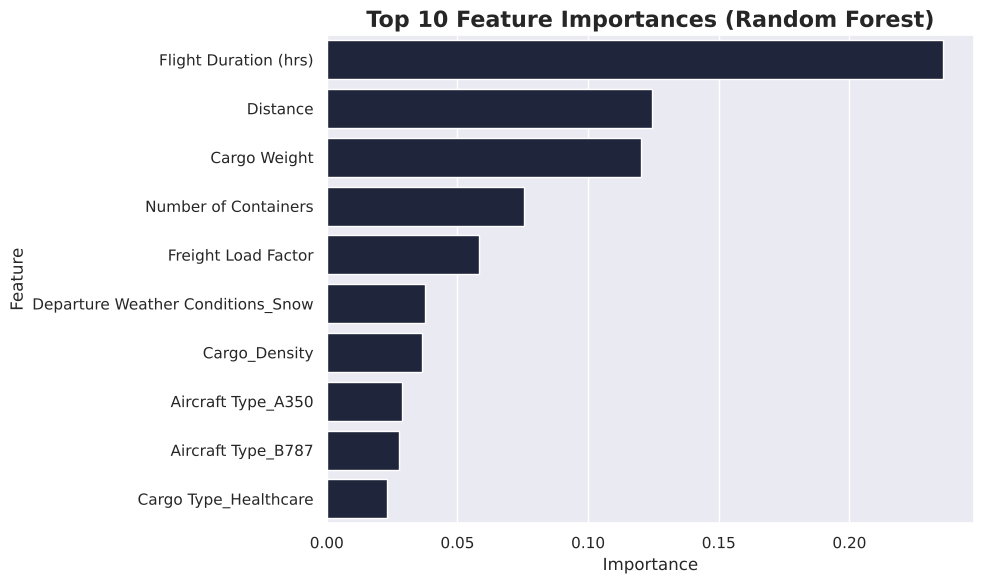

In [49]:
# Standard Feature Importance
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': models['Random Forest'].feature_importances_})
plot_bar('Importance', 'Feature', feature_importance.sort_values('Importance', ascending=False).head(10),
         'Top 10 Feature Importances (Random Forest)', 'Importance', 'Feature', figsize=(10, 6))


Variance Inflation Factor (VIF):
   VIF Factor               features
0    1.433393  Flight Duration (hrs)
1    1.247634               Distance
2    1.296888           Cargo Weight


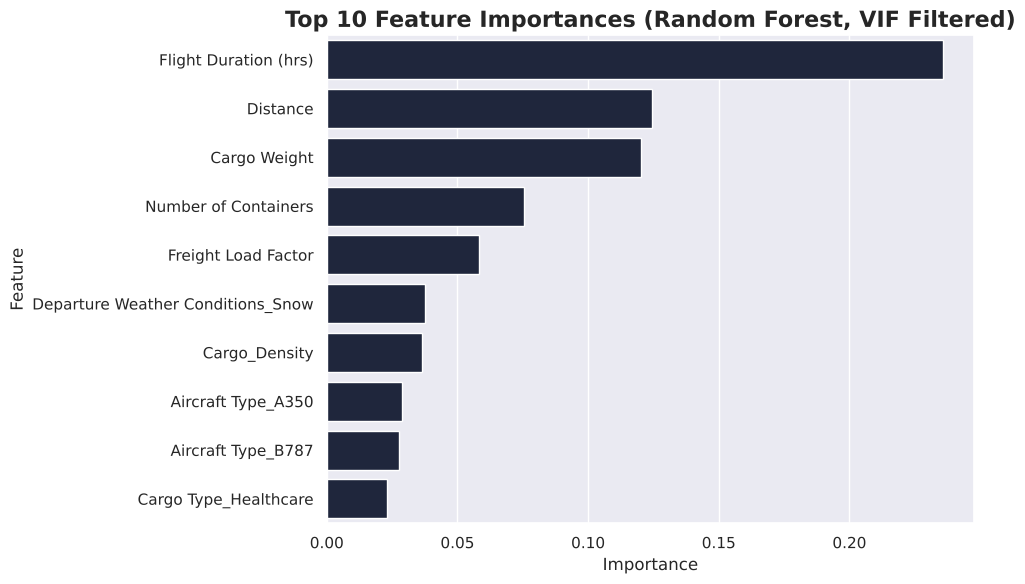

In [50]:
def calculate_vif(X):
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    vif = pd.DataFrame()
    vif["VIF Factor"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    vif["features"] = X.columns
    return vif

delay_related_features = ['Flight Duration (hrs)', 'Distance', 'Cargo Weight']
vif_df = calculate_vif(X[delay_related_features])
print("\nVariance Inflation Factor (VIF):")
print(vif_df)

# Merge VIF with feature importance (optional filtering by VIF threshold)
feature_importance = pd.merge(feature_importance, vif_df, left_on='Feature', right_on='features', how='left')
feature_importance.drop('features', axis=1, inplace=True)
feature_importance['VIF Factor'] = feature_importance['VIF Factor'].fillna(1)
vif_threshold = 5
filtered_features = feature_importance[feature_importance['VIF Factor'] <= vif_threshold]
plot_bar('Importance', 'Feature', filtered_features.sort_values('Importance', ascending=False).head(10),
         'Top 10 Feature Importances (Random Forest, VIF Filtered)', 'Importance', 'Feature', figsize=(10, 6))

**Result:** planned flight duration is by far the most important feature, followed by distance and cargo weight, then container count, freight load factor, snow, cargo density and aircraft type. These are intuitive, operational drivers that stakeholders can relate to directly. The VIF check (all below 1.5) shows the top numerical features are not redundant with each other.

## Learning Curve for Random Forest

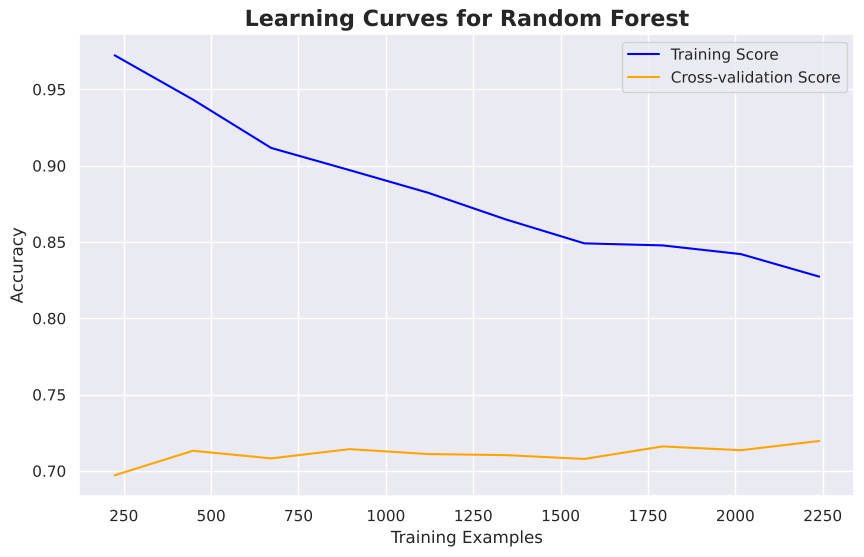

In [51]:
train_sizes, train_scores, test_scores = learning_curve(models['Random Forest'], X_train_scaled, y_train, cv=5,
                                                        n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10),
                                                        scoring='accuracy')
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training Score', color='blue')
plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation Score', color='orange')
plt.xlabel('Training Examples')
plt.ylabel('Accuracy')
plt.title('Learning Curves for Random Forest', fontsize=16, fontweight='bold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

**Result:** training accuracy falls from about 0.97 to 0.83 as more data is added, while validation accuracy stays around 0.71 to 0.72. Limiting tree depth keeps the gap smaller than an unconstrained forest would have, and the model continues to benefit from more data.

# XGBoost

XGBoost (Extreme Gradient Boosting) is a powerful gradient boosting algorithm known for its high performance in various machine learning tasks. It works by iteratively building an ensemble of weak learners (typically decision trees) to create a strong predictive model.

## Training the XGBoost

In [52]:
import xgboost as xgb
from xgboost import XGBClassifier

In [53]:
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Predictions and Evaluation of XGBOOST


In [54]:
xgb_predictions = xgb_model.predict(X_test_scaled)

In [55]:
print(classification_report(y_test,xgb_predictions))

              precision    recall  f1-score   support

           0       0.70      0.75      0.73       571
           1       0.76      0.71      0.73       629

    accuracy                           0.73      1200
   macro avg       0.73      0.73      0.73      1200
weighted avg       0.73      0.73      0.73      1200



In [56]:
print(confusion_matrix(y_test, xgb_predictions))

[[430 141]
 [183 446]]


**Result (baseline XGBoost):** 73% accuracy with balanced precision (76%) and recall (71%). Untuned, it performs between the baseline Decision Tree and Random Forest.

## Cross validation

In [57]:
cv_scores_xgb = cross_val_score(xgb_model, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("\nXGBoost Cross-Validation Scores (Training):", cv_scores_xgb)
print(f"Average CV Score: {cv_scores_xgb.mean():.2f} (+/- {cv_scores_xgb.std()*2:.2f})")


XGBoost Cross-Validation Scores (Training): [0.69107143 0.66964286 0.71785714 0.71785714 0.68392857]
Average CV Score: 0.70 (+/- 0.04)


**Result:** cross-validation accuracy averages 0.70, with slightly more variation across folds than Random Forest.

## Grid Search For XGBoost

In [58]:
param_grid_xgb = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}
models['XGBoost'], predictions['XGBoost'] = run_grid_search(xgb_model, param_grid_xgb,
                                                              X_train_scaled, y_train,
                                                              X_test_scaled, y_test)

Fitting 5 folds for each of 108 candidates, totalling 540 fits



Best Parameters for XGBClassifier: {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV Score: 0.7350
Test Set Performance:
              precision    recall  f1-score   support

           0       0.70      0.87      0.77       571
           1       0.85      0.66      0.74       629

    accuracy                           0.76      1200
   macro avg       0.77      0.76      0.76      1200
weighted avg       0.78      0.76      0.76      1200



**Result (tuned XGBoost):** the best settings use shallow trees (depth 3) and a low learning rate (0.01). Cross-validation accuracy rises to 0.735 and test accuracy to 76%, with 85% precision and 66% recall. Tuning improved XGBoost more than either of the other models.

## Learning Curve for XGBoost

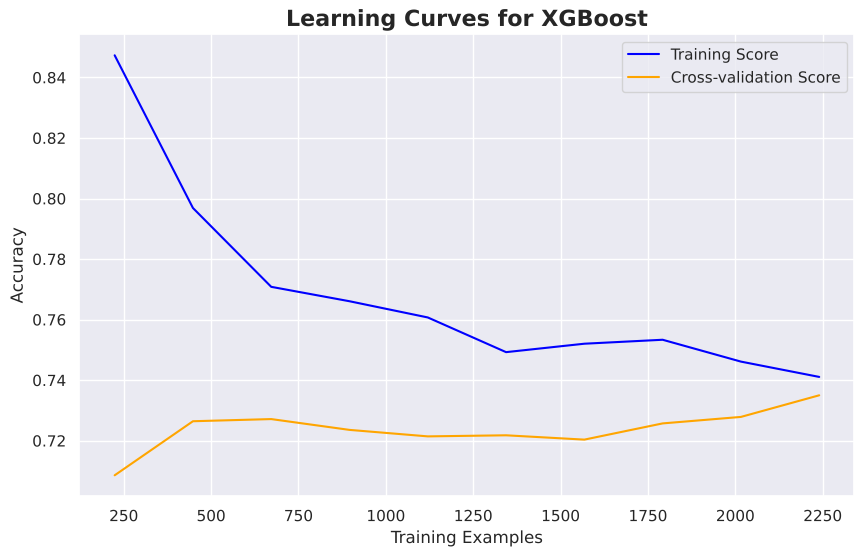

In [59]:
train_sizes, train_scores, test_scores = learning_curve(models['XGBoost'], X_train_scaled, y_train, cv=5,
                                                        n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10),
                                                        scoring='accuracy')
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training Score', color='blue')
plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation Score', color='orange')
plt.xlabel('Training Examples')
plt.ylabel('Accuracy')
plt.title('Learning Curves for XGBoost', fontsize=16, fontweight='bold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

**Result:** training and validation accuracy converge (about 0.74 and 0.73 at full size). The shallow, regularised model generalises well and shows very little overfitting.

# Model Comparison

This section compares the performance of three models. Each model was evaluated using various metrics and techniques to determine the most suitable model for flight delay prediction.

## Evaluation Metrics

The following metrics were considered to assess model performance:

*   **Accuracy:** Measures the overall correctness of the model's predictions.
*   **Precision:** Measures the proportion of correctly predicted delayed flights out of all flights predicted as delayed.
*   **Recall:** Measures the proportion of correctly predicted delayed flights out of all actual delayed flights.
*   **F1 Score:** Provides a balanced measure considering both precision and recall.
*   **ROC-AUC:** Evaluates the model's ability to distinguish between delayed and non-delayed flights.

## Techniques

The following techniques were employed to gain deeper insights into model behavior:

*   **Cross-validation:** Assesses model generalisation and robustness by training and testing on multiple data folds.
*   **Learning Curve:** Visualises the model's learning progress with increasing data size, helping to identify potential overfitting or underfitting.


**Decision Tree:** the gap between training (about 0.84) and validation accuracy (about 0.70) shows the single tree still overfits, even after tuning.

**Random Forest:** training accuracy falls to about 0.83 while validation accuracy holds around 0.72. Averaging many depth-limited trees keeps the model more stable than a single tree.

**XGBoost:** training and validation curves converge (about 0.74 and 0.73), showing the least overfitting of the three.

Overall, the ensemble models generalise better than the single Decision Tree, and all three would benefit from more data.

In [60]:
print("\nModel Comparison...")
results = []
for name, model in models.items():
    preds = predictions[name]
    report = classification_report(y_test, preds, output_dict=True)
    f1 = report['1']['f1-score']
    accuracy = accuracy_score(y_test, preds)
    precision = report['1']['precision']
    recall = report['1']['recall']

    # Use scaled test set for ROC curves (all models trained on scaled data)
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test_scaled)[:, 1])
    roc_auc = auc(fpr, tpr)

    results.append({'Model': name, 'F1 Score': f1, 'Accuracy': accuracy, 'ROC-AUC': roc_auc,
                    'Precision': precision, 'Recall': recall})

results_df = pd.DataFrame(results)
print("\nPerformance Summary (Post-Grid Search):")
print(results_df)


Model Comparison...

Performance Summary (Post-Grid Search):
           Model  F1 Score  Accuracy   ROC-AUC  Precision    Recall
0  Decision Tree  0.743611  0.740833  0.785854   0.772260  0.717011
1  Random Forest  0.682828  0.738333  0.843306   0.936288  0.537361
2        XGBoost  0.740608  0.758333  0.860349   0.846626  0.658188


**Performance summary (test set, after grid search):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Decision Tree | 0.741 | 0.772 | 0.717 | 0.744 | 0.786 |
| Random Forest | 0.738 | 0.936 | 0.537 | 0.683 | 0.843 |
| XGBoost | 0.758 | 0.847 | 0.658 | 0.741 | 0.860 |

**Overall:** all three models land in a similar range (74% to 76% accuracy). These are realistic, moderate scores for predicting delays from pre-departure information alone.

**XGBoost** has the highest accuracy and ROC-AUC, so it is the strongest at ranking flights by delay risk.

**Random Forest** has by far the highest precision (94%): when it flags a delay, it is almost always right. The trade-off is lower recall (54%).

**Decision Tree** has the highest recall (72%) but the weakest ROC-AUC, meaning it catches more delays but with more false alarms and less reliable risk ranking.

The differences in accuracy between the models are small (under two percentage points), so the choice comes down to how each model's behaviour fits the business need.

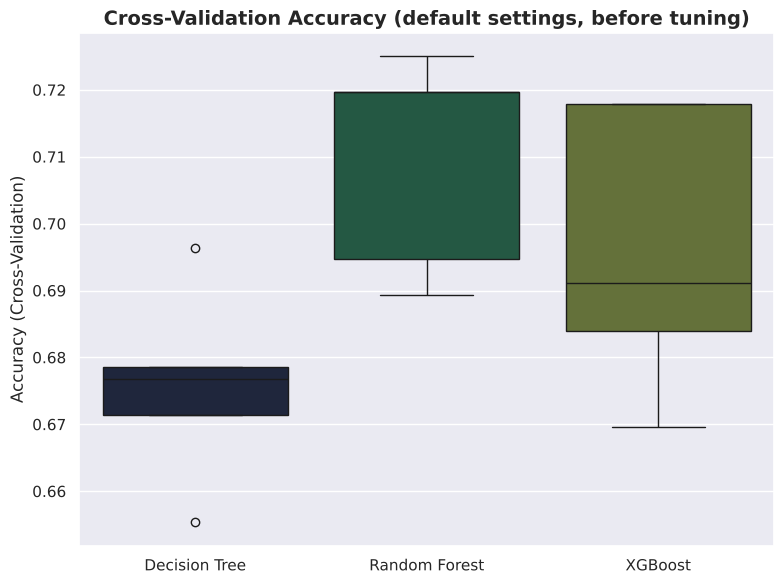

In [61]:
# Cross-validation accuracy from the 5-fold runs above
dt_scores = cv_scores_dt
rf_scores = cv_scores_rf
xgb_scores = cv_scores_xgb

model_names = ['Decision Tree', 'Random Forest', 'XGBoost']
all_scores = [dt_scores, rf_scores, xgb_scores]

plt.figure(figsize=(8, 6))
sns.boxplot(data=all_scores)
plt.xticks(ticks=range(len(model_names)), labels=model_names)
plt.ylabel('Accuracy (Cross-Validation)')
plt.title('Cross-Validation Accuracy (default settings, before tuning)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('images/flight-cv-accuracy.png', dpi=150)
plt.show()

This boxplot compares the 5-fold cross-validation accuracy of the three models with their default settings (before grid search tuning).

Random Forest has the highest median accuracy (about 0.72) with a moderate spread, XGBoost follows (about 0.69) with the widest spread, and the untuned Decision Tree is lowest (about 0.68). After tuning, the best cross-validation scores were 0.703 (Decision Tree), 0.720 (Random Forest) and 0.735 (XGBoost).

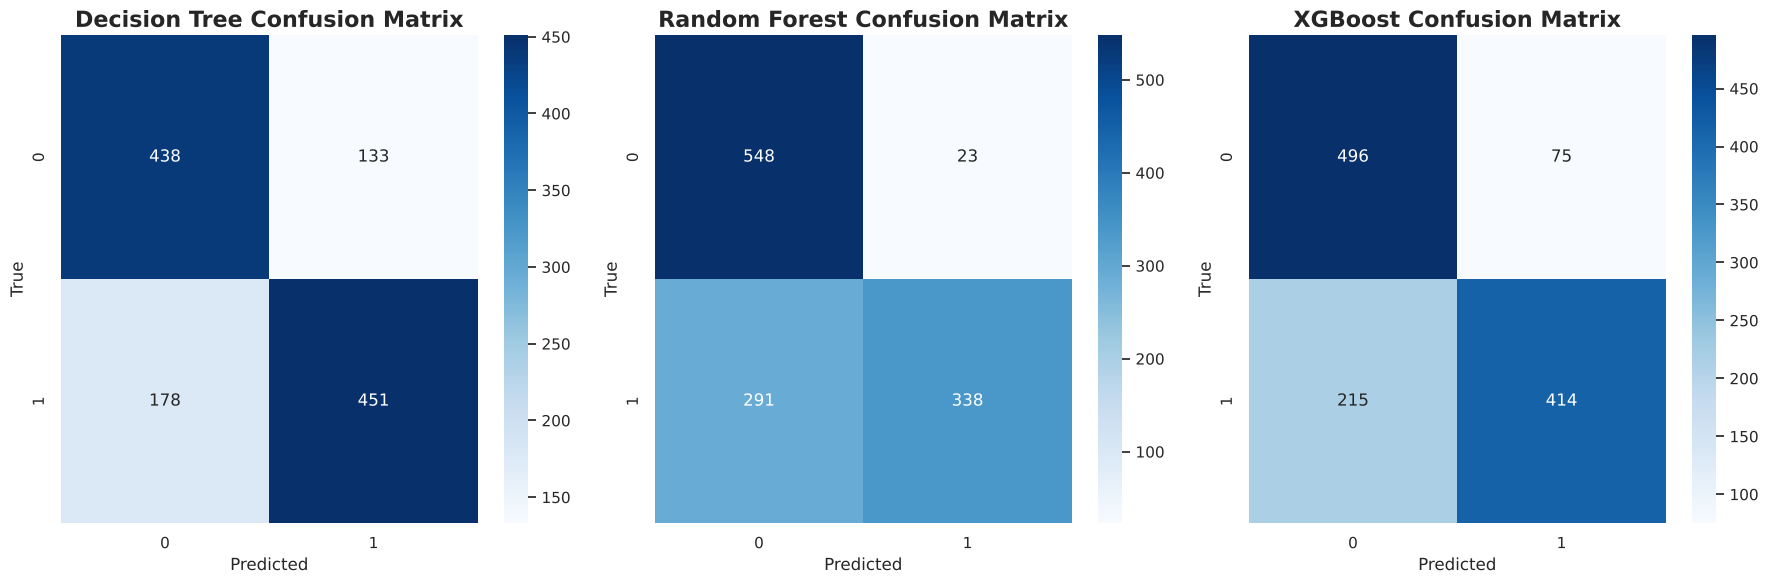

In [62]:
# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, preds) in zip(axes.flatten(), predictions.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'{name} Confusion Matrix', fontsize=16, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
plt.show()



These confusion matrices show where each tuned model gets it right and wrong on the 1,200 test flights (571 on time, 629 delayed).

- **Decision Tree** catches the most delays (451 of 629) but raises the most false alarms (133).
- **Random Forest** raises by far the fewest false alarms (only 23) but misses the most delays (291).
- **XGBoost** sits in between, catching 414 delays with 75 false alarms.

Which model is "best" depends on the operational cost of each type of error: missing a delay (false negative) versus preparing for a delay that does not happen (false positive).

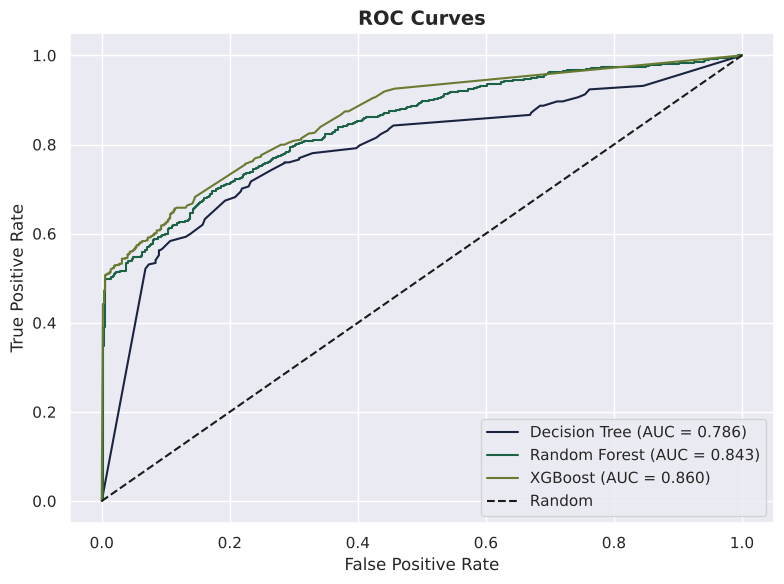

In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ROC Curves
plt.figure(figsize=(8, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test_scaled)[:, 1])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/flight-roc-curves.png', dpi=150)
plt.show()

The ROC curves show each model's ability to separate delayed from on-time flights across all decision thresholds.

- **XGBoost:** AUC 0.86
- **Random Forest:** AUC 0.84
- **Decision Tree:** AUC 0.79

Both ensemble models clearly outperform the single tree. The gap between Random Forest and XGBoost is small, and because AUC is threshold-independent, Random Forest's decision threshold could be lowered to catch more delays if needed.

## Model Selection

Although XGBoost achieved the highest accuracy (75.8%) and ROC-AUC (0.86), **Random Forest was chosen as the final model** for flight delay prediction. This reflects a balance between performance and practical considerations:

**Explainability for stakeholders:** Random Forest provides clear, intuitive feature importance scores (planned flight duration, distance, cargo weight, load), making it easy to explain what drives a prediction to operational and non-technical stakeholders. This transparency builds trust and supports meaningful discussions about preventative actions and contingency planning.

**Proportionate to the dataset:** with 4,000 flights, the extra tuning effort and complexity of gradient boosting is hard to justify. Random Forest performed well with modest tuning, is robust to hyperparameter choices, and is simpler to retrain and maintain.

**Minimal performance trade-off:** the accuracy difference from XGBoost is small (2 percentage points) and the ROC-AUC is close (0.84 vs 0.86). Random Forest is also the most precise model: 94% of the flights it flags are genuinely delayed, so alerts can be acted on with confidence.

**Known limitation:** at the default threshold, Random Forest catches 54% of delays. If missing a delay proves more costly than a false alarm, the decision threshold can be lowered to increase recall, and its ROC-AUC of 0.84 shows there is room to do so.

### Key Takeaways

**Model performance:** all three models achieved realistic accuracy of 74% to 76% using only information available before departure, with ROC-AUC between 0.79 and 0.86.

**Top performer:** XGBoost achieved the highest accuracy and ROC-AUC. However, Random Forest was selected for its balance of strong predictive performance, explainability and suitability for a dataset of this size.

**Strengths of the Random Forest model:**

- Very high precision (94%), so flagged flights are almost always genuinely at risk.
- Stable performance across cross-validation folds.
- Clear feature importance rankings that point to intuitive operational drivers.
- Simple to tune, retrain and explain.

**Model selection rationale:** the right model depends on the goals and constraints of the project. Here, the ability to explain predictions to stakeholders and keep the solution proportionate outweighed a small gain in accuracy.

**Considerations regarding model performance**

- **Leakage checks:** the first version of this notebook reported over 99% accuracy because some features were only known after a delay had happened (see the version note at the top). Every feature should be checked for whether it would really be available at the time of prediction. Results that look too good to be true usually are.
- **Threshold tuning:** the decision threshold should be set based on the cost of a missed delay versus a false alarm, rather than the default of 0.5.
- **Dataset complexity:** the dataset is synthetic and relatively small. Performance on real operational data, with richer real-time inputs such as en-route weather, airport congestion and handling milestones, would need to be validated.
- **External validation:** where possible, the model should be tested on an independent dataset or a later time period before any operational use.